# Stage 3 | Try World-Gymnast-inspired RL inside WorldGym

**This stage has actually run. The learning process worked, but reliable policy gains have not been established.**

The first two notebooks explained how to learn actions and how to evaluate a fixed policy. This lesson takes roughly 20 minutes and follows five panels to explain how imagined experience becomes a policy update—and why the measured outcomes did not establish the hoped-for benefit.

![Stage 3 overview: the roles of SmolVLA, native WorldGym and a VLM, four-rollout GRPO groups, the five policy outcomes, diagnostic evidence and a proposed next experiment.](media/figures/03_next_rl.png)

[Open the full-size overview](media/figures/03_next_rl.png). Panels 1–4 describe completed work. Panel 5 is a **DRAFT next experiment, NOT EXECUTED**.

## 1 Which models do what?

**The three models in the upper-left panel have three different jobs.**

| Component | Input → output | Role in this stage |
|---|---|---|
| SmolVLA policy | Images, joint state and task language → joint/gripper targets | Chooses actions; its trainable policy parameters receive the RL updates |
| Native WorldGym + VAE | Current context and actions → future images; a separate learned predictor supplies joint observations | Provides the future observations used for subsequent decisions |
| Qwen2.5-VL-7B reward model | Trajectory images and task description → reward score | Judges imagined task completion; it does not control the robot |

**This branch changes the policy from ACT to SmolVLA.** SmolVLA accepts vision and language and produces actions, making it suitable for exploring language-conditioned VLA updates. We adapted the method to one RTX 4080 SUPER with 16 GB. This is neither ACT under a new name nor an exact reproduction of the original large-scale OpenVLA/token-GRPO setup.

RL does not start from completely random behavior. SmolVLA first receives supervised fine-tuning: its pretrained action expert and projection modules are trained while the vision/language backbone remains frozen. Development performance selects among saved checkpoints. This round completed 15,000 SFT steps and selected the 7,500-step checkpoint. The RL comparison arms then start from **the same SFT policy**.

“Native” has a specific meaning here. Simulator reset supplies the initial observation; WorldGym/VAE generates future images, and a learned predictor supplies future joint state. True future MuJoCo images do not replace generated images at each step. Actions remain seven-dimensional joint/gripper targets under the task's action interface.

## 2 What happens in one RL group?

**The four film strips start from the same initial state.** Stochastic policy sampling gives different attempted behaviors. Each rollout repeats “policy action → WorldGym future observation → next policy action,” producing a complete imagined trajectory. Each trajectory in this round saves 114 frames.

The VLM scores the images against the instruction to pick up and lift the tube. The central intuition of **GRPO** is to compare rewards within a group: make relatively high-reward actions more likely and relatively low-reward actions less likely, while constraining the update's departure from the reference policy. The reward model is fixed during main policy RL; the policy is what changes.

For a teaching example, suppose four rewards are 0.2, 0.8, 0.4 and 0.6. Their mean is 0.5. The second is above the group mean and the first below it, providing a relative learning signal. **These are illustrative numbers, not measured rewards or an executed training step.**

In [1]:
from briefing_utils import *
verify_assets()
toy_rewards = np.array([0.2, 0.8, 0.4, 0.6])
table([[i + 1, r, round(r - toy_rewards.mean(), 2)] for i, r in enumerate(toy_rewards)],
      ['Illustrative rollout', 'Toy reward', 'Reward minus group mean'])

Illustrative rollout,Toy reward,Reward minus group mean
1,0.2,-0.3
2,0.8,0.3
3,0.4,-0.1
4,0.6,0.1


Actual training additionally uses action probabilities, clipped probability ratios and a KL constraint. Our resource adaptation treats SmolVLA's deterministic flow output as the **mean of a Gaussian policy** and updates using sampled actions and their matching log-probabilities. SFT action MSE is not substituted for an RL likelihood. Trainable parameters and optimizer state use FP32 with BF16 autocast, and saved update records support numerical recomputation.

The main comparison uses **16 groups × four rollouts**. A matched MuJoCo GRPO arm uses the same SFT start, VLM reward, sampling and optimization settings, while MuJoCo supplies the future observations. That arm also trains with the VLM reward: it is **not** an official-success-reward control. Both arms are finally tested in MuJoCo under the official task criterion.

Two extensions also ran:

| Extension | What ran | Why the comparison matters |
|---|---|---|
| **Dyna** | Update the world model for 500 steps using new physical trajectories, then continue policy RL for eight groups | Compare against eight additional groups without updating the world model, separating extra RL from model improvement |
| **TTT**, initial-observation adaptation | Adapt separately for four scenes using only their initial observations and model rollouts, then test in physical simulation | No future test labels are read for adaptation; the sample is too small for broad conclusions |

> Evidence that RL happened includes actual generated trajectories, VLM scores, changed policy weights and recomputed likelihood/optimizer updates. A flowchart or a reward value alone would not establish training.

## 3 What actually happened

**Read the denominator before interpreting the five results.** All five fixed policies were tested on the same 100 new MuJoCo initial states, giving 500 trials. These states differ from the earlier stages. Training and selection were frozen before the final results were read.

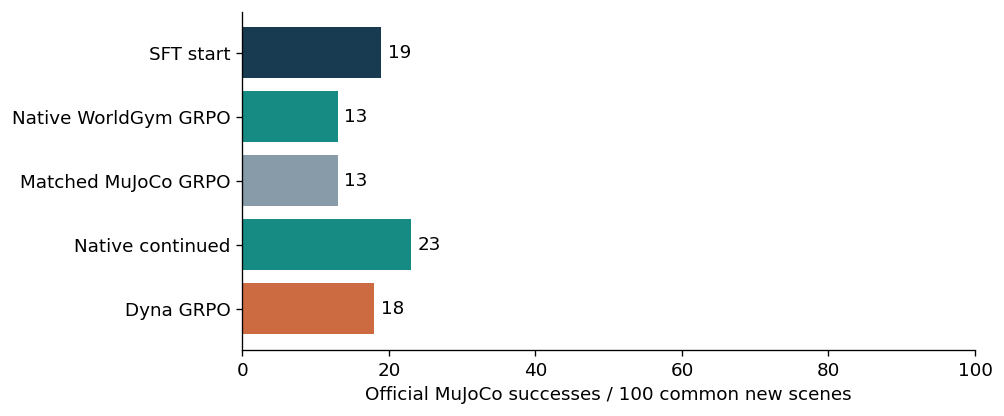

Paired comparison,Change (pp),Improved scenes,New failures,Archived 95% interval (pp)
native_GRPO - SFT,-6,6,12,"[-14, 2]"
Dyna_GRPO - native_continued,-5,11,16,"[-15, 5]"


In [2]:
native_results()

The SFT start succeeded in **19/100** scenes; both first-round native GRPO and matched MuJoCo GRPO scored **13/100**. Equal totals do not imply identical scene-level behavior or equivalent training environments.

Compared with SFT, native GRPO produced **six improved scenes and 12 new failures**: a net change of −6 percentage points, with a scene-paired 95% interval of approximately [−14,+2]. Showing only the six improvements would misrepresent the result.

Native continuation scored **23/100**, and Dyna **18/100**. The key Dyna comparison is 18 against the equally continued policy's 23, rather than only against the SFT start. TTT scored 0/4 both before and after adaptation. This shows no benefit in those scenes, but does not establish universal ineffectiveness.

The **engineering learning loop is demonstrated**; **stable policy performance gains are not**. Scene-paired intervals describe uncertainty over these initial states, not variation across independent training runs. This remains one pickup task with one policy-training seed.

## 4 Why stable gains remain unproven

**Look at the chain: prediction → reward → update.** If the world model predicts contact or lifting incorrectly, the reward judges an incorrect future. Even with correct images, the VLM can misjudge success. Effective optimization of a score need not improve the physical objective. This is a mechanism to investigate, not a proven single cause of failure.

Subsequent diagnosis and repair produced the following evidence. These are **separate experiments**, not new outcomes for the five policies above.

**World-model diagnosis.** Two arms started from the same model and trained for a matched 500 steps: replay historical data, or mix in stationary-action data (“hold-mix”). A complete comparison used four new initial states, three actions and three models: 36 predictions. Hold-mix reduced stationary-image error by about 33% relative to replay-only, but worsened movement and reversed-gripper predictions. Pixel MAE measures the average difference between predicted and physical-simulation images; lower is closer, but it is not pickup success.

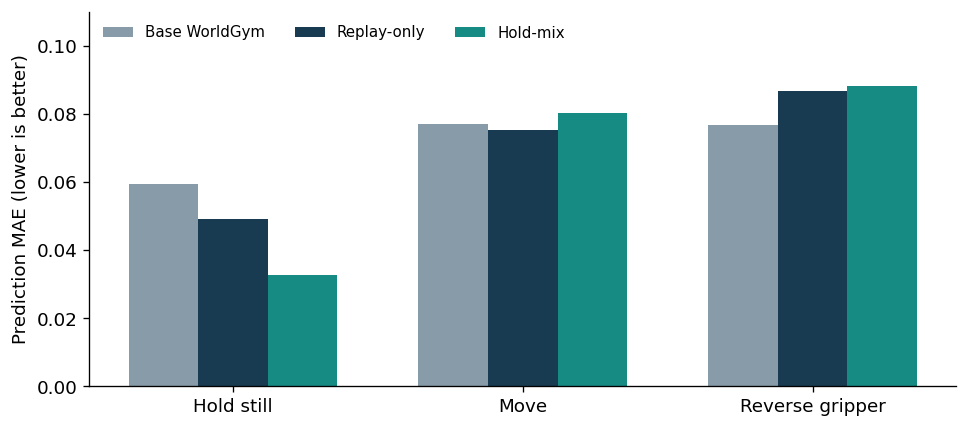

In [3]:
model_action_plot()

This demonstrates that making images stay still can improve without improving action response overall. Pure VAE static encoding/decoding error was about 0.0059, versus approximately 0.0594 for base native static prediction. Image compression therefore does not explain all the drift. Inspect the same fixed case in the [stationary comparison](media/demos/world_model_static.mp4) and [movement comparison](media/demos/world_model_motion.mp4), not only the averages.

**Reward diagnosis.** Validation used 12 new scenes × two policies × eight frames. The repaired VLM reduced false positives from 18 to six, but increased false negatives from zero to 27; balanced accuracy fell from about 91.6% to 81.3%. Frames within a trajectory are correlated: this is not 192 independent environment experiments. Another paired generated/physical-image diagnostic had only one physical positive, which both VLM versions missed on generated images. That is insufficient positive coverage to certify the reward.

**Policy-start diagnosis.** In another independent 100-scene confirmation, additional SFT increased SmolVLA from 19 to 53 successes, while strong ACT40 scored 91. The +34-point change contained 44 improvements and ten new failures. This is an additional-supervision result, **not a WorldGym RL result**. Original-learning-rate mixed-precision continuation already reached 52, versus 53 for the development-selected scaled rate; the whole gain cannot be assigned to learning-rate scaling. Better FP32 numerical update resolution also did not establish a physical success benefit.

<details><summary>Optional: the complete later SFT comparison and both kinds of replay</summary>

[All six conditions](evidence/repair_results.json) include the original SFT, two learning rates × two precision settings, and ACT40. Videos preserve both the [first improvement](media/demos/policy_improvement.mp4) and the [first regression](media/demos/policy_regression.mp4), rather than only a favorable case.

</details>

## 5 How to continue

**This panel is a proposal, not another completed result.** A useful next question is whether repairing action/contact predictions for the current policy makes imagined rewards more informative and produces an attributable RL benefit.

First, use identical fixed initial observations and action sequences in native WorldGym and MuJoCo. Check whether the predicted action effects resemble physical effects. Apply the same frozen VLM to both image sets to separate future-prediction errors from visual-judgment errors.

Then fix the SFT start, reward model and RL budget. Compare two matched world-model training conditions: historical replay and a version with action/contact repair data. Retain SFT, MuJoCo RL, both model-RL conditions and strong ACT as references. Run the complete matrix on new initial states fixed before final evaluation, reporting both improvements and new failures.

| What must be fixed or retained | What this separates |
|---|---|
| Same SFT start and VLM reward | Extra supervision or a different reward from model improvements |
| Matched model-training steps and RL rollout budget | Additional computation from a method's benefit |
| Replay-only world-model control | Whether targeted repair data adds value |
| Independent final states, strong ACT and all failures | Physical task improvement from merely higher imagined scores |

There is no basis yet to promise a particular success-rate increase. A concrete research question for discussion is how to balance pixel fidelity, action-outcome fidelity and reward reliability on generated images in contact-sensitive tasks.

**Executable entries:** [native GRPO](Scripts/train_native_rl.py), [model and physical evaluation](Scripts/evaluate.py), [numerical audits](Scripts/audit.py), and the [running guide](Scripts/README.md). This compact release includes core SFT/native RL, but not portable orchestration for every historical Dyna/TTT stage. Task-specific weights are not published. The CPU lessons run from a clone; complete GPU execution still requires the matching assets.

**A precise research summary:** “I implemented a compact, single-GPU World-Gymnast-inspired learning loop in which native world-model futures and a task-adapted VLM reward drive actual policy updates. Matched physical evaluation did not establish reliable gains, motivating controlled diagnosis of action prediction, reward transfer and the SFT starting policy.”

**Connect the three stages:** Stage 1 changes a policy to learn actions. Stage 2 freezes policies and checks evaluation quality. Stage 3 uses model rewards to change a policy again, then tests it in physical simulation. Their metrics, policy architectures and test batches must be explained separately.

[Back to Stage 1](01_act_imitation_learning.ipynb) · [Back to Stage 2](02_worldgym_policy_evaluation.ipynb)

<details><summary>Evidence sources and scope</summary>

[Native RL summary](evidence/native_summary.json), [all 500 final outcomes](evidence/native_outcomes.csv), [later diagnostics](evidence/repair_diagnostics.json) and [paired world-model repair results](evidence/wm_paired_summary.json). This revision reorganizes teaching and CPU verification. It does not retrain models or add generalization evidence. All outcomes concern simulation, not real robots, wet-lab deployment or surgery.

</details>